<a href="https://colab.research.google.com/github/Nosimon-Nahar/LabReport-3_CSE-418/blob/main/Masks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

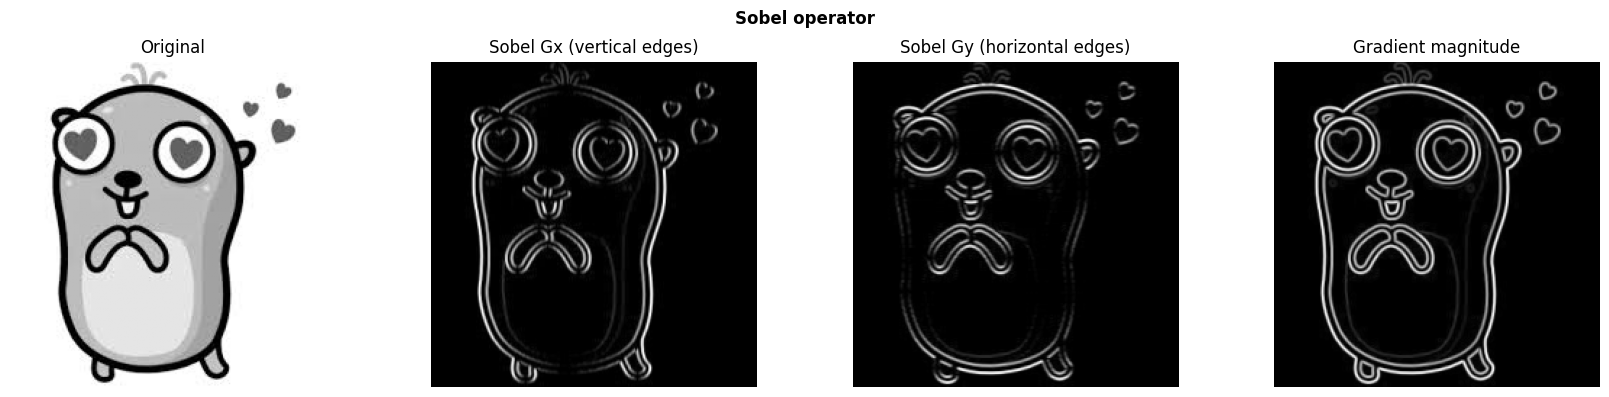

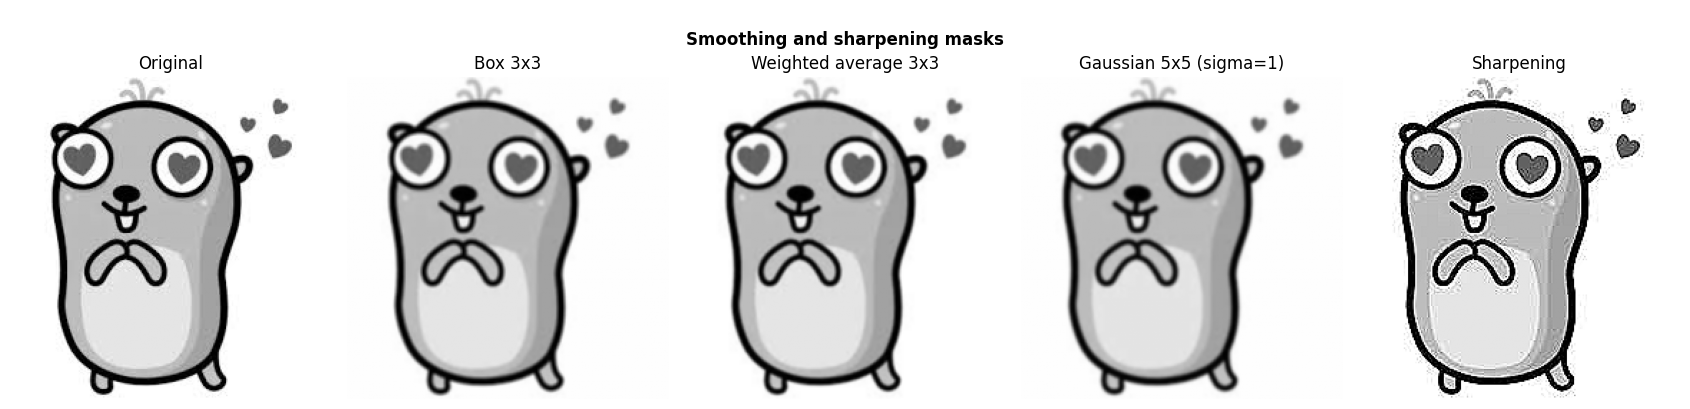

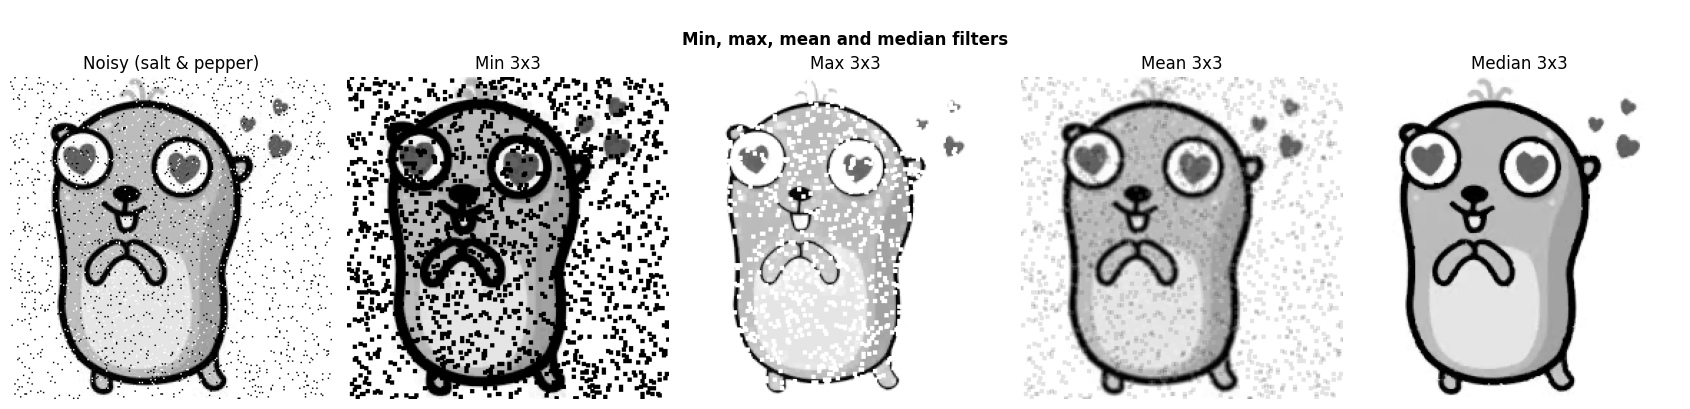

In [1]:
""" Applying different masks to a single image
  a. Sobel operator
  b. Box filter
  c. Weighted average filter
  d. Gaussian filter mask
  e. Sharpening filter
  f. Min, max, mean and median filters """
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt

def load_gray(path=None):
  # Load grayscale image; fall back to a synthetic test image.
    if path:
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            raise ValueError(f"Could not read image: {path}")
        return img
    x, y = np.meshgrid(np.linspace(0, 1, 512), np.linspace(0, 1, 512))
    img = 80 + 60 * x + 30 * np.sin(12 * y) * np.cos(8 * x)
    cv2.circle(img, (256, 256), 100, 170, -1)
    cv2.rectangle(img, (60, 60), (160, 160), 220, -1)
    return np.clip(img, 0, 255).astype(np.uint8)

def clip_u8(a):
    return np.clip(a, 0, 255).astype(np.uint8)

def normalize_u8(a):
  # Scale any array to 0..255 for display (used for signed edge results).
    a = a.astype(np.float64)
    rng = a.max() - a.min()
    return np.zeros(a.shape, np.uint8) if rng < 1e-12 else ((a - a.min()) / rng * 255).astype(np.uint8)

def convolve(img, kernel):
  # Apply a mask to the image (float result, replicated borders).
    return cv2.filter2D(img.astype(np.float32), cv2.CV_32F,
                        np.asarray(kernel, np.float32), borderType=cv2.BORDER_REPLICATE)

def gaussian_kernel(size=5, sigma=1.0):
  # Normalized 2-D Gaussian mask.
    ax = np.arange(size) - size // 2
    xx, yy = np.meshgrid(ax, ax)
    k = np.exp(-(xx ** 2 + yy ** 2) / (2.0 * sigma ** 2))
    return k / k.sum()

def add_salt_pepper(img, amount=0.06, seed=0):
  # Impulse noise so the min/max/mean/median differences are visible.
    rng = np.random.default_rng(seed)
    noisy = img.copy()
    r = rng.random(img.shape)
    noisy[r < amount / 2] = 0
    noisy[r > 1 - amount / 2] = 255
    return noisy

# ---------------- Masks ----------------
SOBEL_X = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
SOBEL_Y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], np.float32)
BOX = np.ones((3, 3), np.float32) / 9.0
WEIGHTED_AVG = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], np.float32) / 16.0
SHARPEN = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], np.float32)

# ---------------- Rank / order-statistic filters ----------------
def min_filter(img, k=3):
    return cv2.erode(img, np.ones((k, k), np.uint8), borderType=cv2.BORDER_REPLICATE)

def max_filter(img, k=3):
    return cv2.dilate(img, np.ones((k, k), np.uint8), borderType=cv2.BORDER_REPLICATE)

def mean_filter(img, k=3):
    return cv2.blur(img, (k, k), borderType=cv2.BORDER_REPLICATE)

def median_filter(img, k=3):
    return cv2.medianBlur(img, k)

def show(images, titles, title, fname, figsize):
    fig, axes = plt.subplots(1, len(images), figsize=figsize)
    for ax, im, t in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(t, fontsize=12)
        ax.axis("off")
    fig.suptitle(title, fontweight="bold")
    fig.tight_layout()
    fig.savefig(fname, dpi=120)

def main():
    img = load_gray("/content/images (1).jpg")

  # Sobel operation
    gx, gy = convolve(img, SOBEL_X), convolve(img, SOBEL_Y)
    magnitude = np.sqrt(gx ** 2 + gy ** 2)
    show([img, normalize_u8(np.abs(gx)), normalize_u8(np.abs(gy)), normalize_u8(magnitude)],
         ["Original", "Sobel Gx (vertical edges)", "Sobel Gy (horizontal edges)", "Gradient magnitude"],
         "Sobel operator", "sobel.png", (17, 4))

  # Box, weighted average, Gaussian, sharpening
    box = clip_u8(convolve(img, BOX))
    wavg = clip_u8(convolve(img, WEIGHTED_AVG))
    gauss = clip_u8(convolve(img, gaussian_kernel(5, 1.0)))
    sharp = clip_u8(convolve(img, SHARPEN))
    show([img, box, wavg, gauss, sharp],
         ["Original", "Box 3x3", "Weighted average 3x3",
          "Gaussian 5x5 (sigma=1)", "Sharpening"],
         "\nSmoothing and sharpening masks", "sharpening_filters.png", (17, 4.2))

  # Min, max, mean, median (on a noisy copy)
    noisy = add_salt_pepper(img)
    show([noisy, min_filter(noisy), max_filter(noisy), mean_filter(noisy), median_filter(noisy)],
         ["Noisy (salt & pepper)", "Min 3x3", "Max 3x3", "Mean 3x3", "Median 3x3"],
         "\nMin, max, mean and median filters", "rank_filters.png", (17, 4.2))
    plt.show()

if __name__ == "__main__":
    main()